In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

caminho = Path("/content/sic_wellness_emily_park.xlsx")

df = pd.read_excel(caminho)

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,participant_id,date,day,age,gender,height_cm,weight_kg,daily_steps,activity_type,activity_intensity,activity_duration_min,activity_calories_burned,activity_avg_heart_rate,resting_heart_rate,sleep_hours,stress_level,stress_category,target_sleep_hours,target_activity_duration,target_daily_steps
0,Emily Park,2025-01-01,Wed,35,F,168.7,65,6140,Walking,Low,40,117,114.0,66.5,7.5,4,Moderate,8,40,5000
1,Emily Park,2025-01-02,Thu,35,F,168.7,65,7301,Walking,Medium,29,60,159.0,66.6,7.8,5,Moderate,8,40,5000
2,Emily Park,2025-01-03,Fri,35,F,168.7,65,10130,Walking,Medium,87,197,141.0,66.6,7.6,4,Moderate,8,40,5000
3,Emily Park,2025-01-04,Sat,35,F,168.7,65,7979,HIIT,Low,31,134,112.0,66.7,8.5,4,Moderate,8,40,5000
4,Emily Park,2025-01-05,Sun,35,F,168.7,65,6636,Walking,Low,60,63,122.0,66.5,8.6,4,Moderate,8,40,5000


In [ ]:
# 1. Selecionar apenas as colunas numéricas
df_numerico = df.select_dtypes(include=np.number)

# 2. Calcular os resumos estatísticos e arredondar para 1 casa decimal
resumo = df_numerico.describe().round(1)

# 3. Inverter a tabela (transpor) para trocar linhas e colunas
resumo_transposto = resumo.T

resumo_transposto

,count,mean,std,min,25%,50%,75%,max
age,365.0,35.0,0.0,35.0,35.0,35.0,35.0,35.0
height_cm,365.0,168.7,0.0,168.7,168.7,168.7,168.7,168.7
weight_kg,365.0,65.0,0.0,65.0,65.0,65.0,65.0,65.0
daily_steps,365.0,8938.9,3463.7,1531.0,6623.0,8310.0,11031.0,26223.0
activity_duration_min,365.0,68.4,29.2,10.0,42.0,70.0,90.0,123.0
activity_calories_burned,365.0,354.2,239.4,25.0,171.0,311.0,479.0,1186.0
activity_avg_heart_rate,365.0,134.7,16.3,80.2,122.0,135.0,147.0,175.0
resting_heart_rate,365.0,56.5,6.2,50.0,52.0,53.2,62.5,68.6
sleep_hours,365.0,6.8,1.8,3.7,5.4,6.7,8.0,10.1
stress_level,365.0,5.6,1.1,3.0,5.0,6.0,6.0,9.0


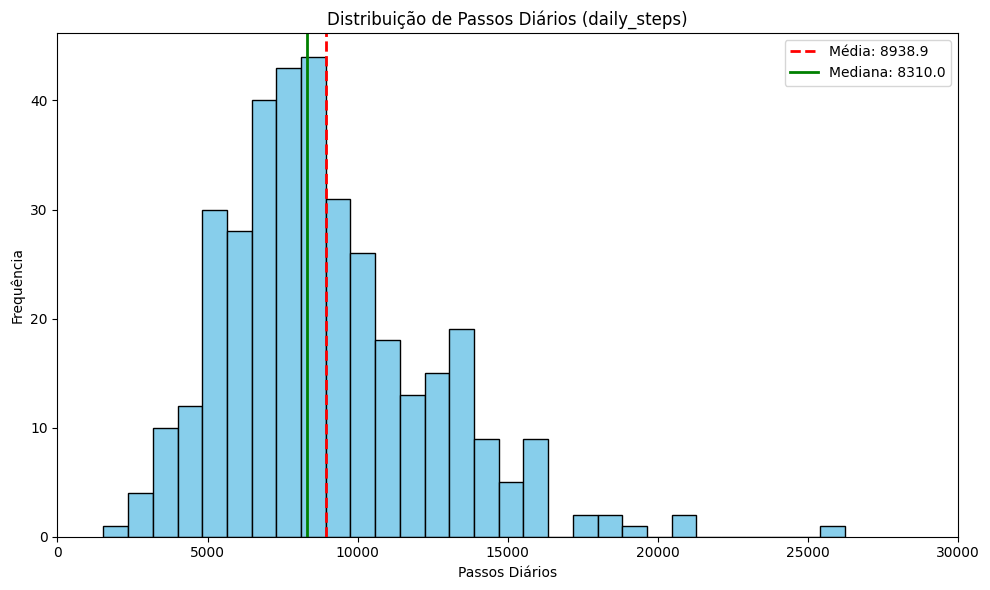

In [ ]:
# Calculando média e mediana
media = df['daily_steps'].mean()
mediana = df['daily_steps'].median()

# 2. Criando o histograma
plt.figure(figsize=(10, 6))
plt.hist(df['daily_steps'], bins=30, color='skyblue', edgecolor='black')

plt.title('Distribuição de Passos Diários (daily_steps)')
plt.xlabel('Passos Diários')
plt.ylabel('Frequência')

# 3. Definindo o intervalo das marcações do eixo X em 5.000
x_min = 0
x_max = df['daily_steps'].max()
plt.xticks(np.arange(x_min, x_max + 5000, 5000))

# 4. Linhas verticais para média e mediana
plt.axvline(media, color='red', linestyle='--', linewidth=2, label=f'Média: {media:.1f}')
plt.axvline(mediana, color='green', linestyle='-', linewidth=2, label=f'Mediana: {mediana:.1f}')

plt.legend()
plt.tight_layout()
plt.show()

/tmp/ipykernel_689/4131884123.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = plt.boxplot(dados_boxplot, labels=rotulos_pt, patch_artist=True)


<Figure size 1000x600 with 0 Axes>

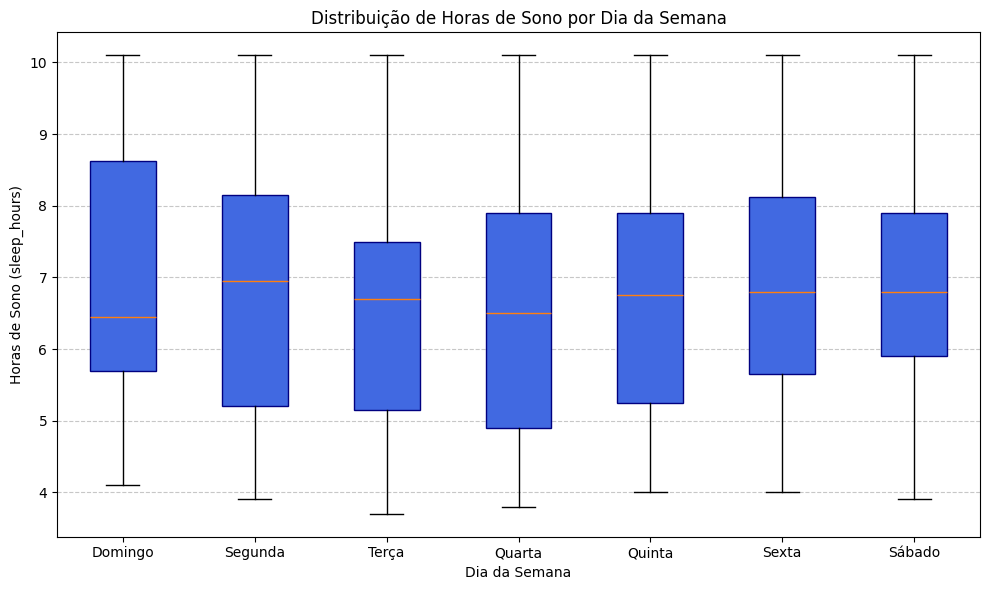

In [ ]:
# 1. Ordem dos dias (valores reais no df) e seus rótulos em português
ordem_dias = ['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat']
rotulos_pt = ['Domingo', 'Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado']

# Agrupando os dados de sleep_hours por dia da semana, na ordem definida
dados_boxplot = [df[df['day'] == dia]['sleep_hours'].dropna() for dia in ordem_dias]

# 2. Criando o box plot
plt.figure(figsize=(10, 6))
plt.figure(figsize=(10, 6))
box = plt.boxplot(dados_boxplot, labels=rotulos_pt, patch_artist=True)

# Colorindo as caixas de azul
for caixa in box['boxes']:
    caixa.set_facecolor('royalblue')
    caixa.set_edgecolor('navy')

plt.title('Distribuição de Horas de Sono por Dia da Semana')
plt.xlabel('Dia da Semana')
plt.ylabel('Horas de Sono (sleep_hours)')

# 3. Adicionando linhas de grade horizontais no eixo Y
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

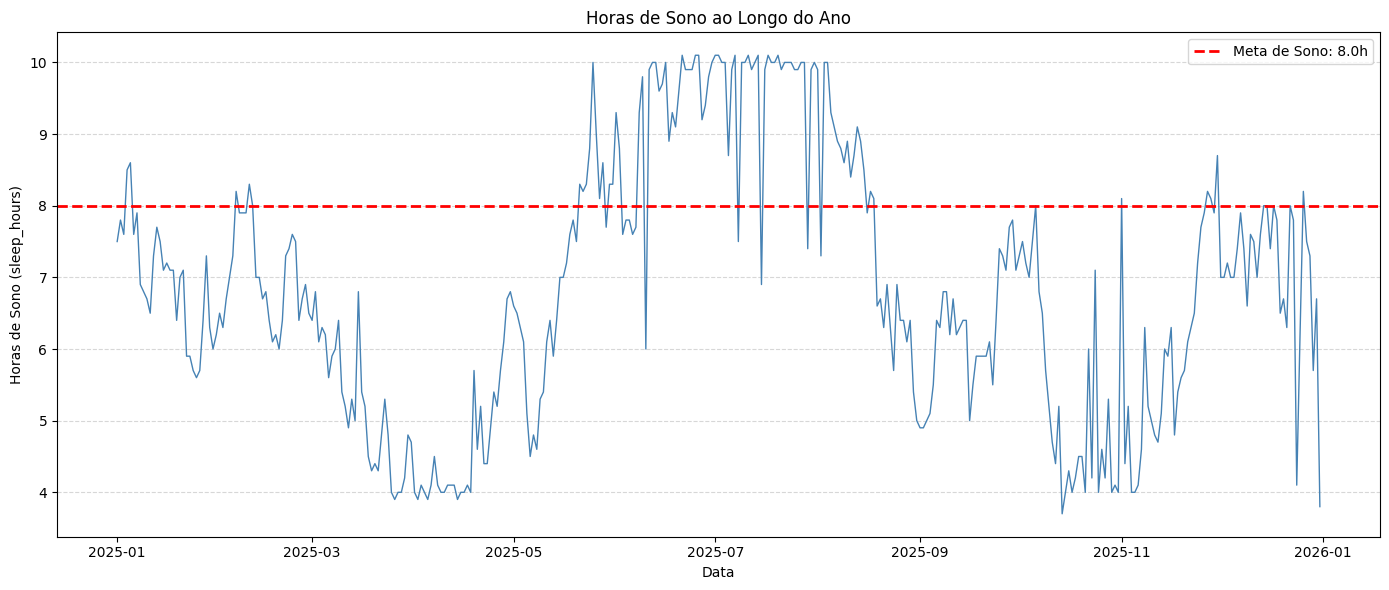

In [ ]:
# Garantindo que a coluna de data está no formato correto
df['date'] = pd.to_datetime(df['date'])

# 1. Ordenando o DataFrame pela data
df_ordenado = df.sort_values('date')

# 2. Criando o gráfico de série temporal
plt.figure(figsize=(14, 6))
plt.plot(df_ordenado['date'], df_ordenado['sleep_hours'], color='steelblue', linewidth=1)

plt.title('Horas de Sono ao Longo do Ano')
plt.xlabel('Data')
plt.ylabel('Horas de Sono (sleep_hours)')

# 3. Linha horizontal para a meta de sono (target_sleep_hours)
meta_sono = df_ordenado['target_sleep_hours'].iloc[0]
plt.axhline(meta_sono, color='red', linestyle='--', linewidth=2,
            label=f'Meta de Sono: {meta_sono:.1f}h')

plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# Garantindo que a coluna de data está no formato correto
df['date'] = pd.to_datetime(df['date'])

# 1. Encontrando a data mais recente no DataFrame
data_mais_recente = df['date'].max()

# 2. Definindo o intervalo dos últimos 7 dias
data_inicio = data_mais_recente - pd.Timedelta(days=6)

last_7days = df[(df['date'] >= data_inicio) & (df['date'] <= data_mais_recente)]

# 3. Mostrando o intervalo de datas e confirmando que são 7 dias
print(f"Data mais recente: {data_mais_recente.date()}")
print(f"Data de início: {data_inicio.date()}")
print(f"Intervalo: {data_inicio.date()} até {data_mais_recente.date()}")
print(f"Número de dias no intervalo: {last_7days['date'].nunique()}")

Data mais recente: 2025-12-31
Data de início: 2025-12-25
Intervalo: 2025-12-25 até 2025-12-31
Número de dias no intervalo: 7


In [ ]:
# Calculando as métricas de resumo semanal
media_sono = last_7days['sleep_hours'].mean()
media_estresse = last_7days['stress_level'].mean()
media_passos = last_7days['daily_steps'].mean()
media_exercicio = last_7days['activity_duration_min'].mean()

print(f"Média de Horas de Sono: {media_sono:.1f} h")
print(f"Média do Nível de Estresse: {media_estresse:.1f}")
print(f"Média de Passos Diários: {media_passos:.1f}")
print(f"Média de Tempo de Exercício: {media_exercicio:.1f} min")

Média de Horas de Sono: 6.5 h
Média do Nível de Estresse: 4.7
Média de Passos Diários: 7358.4
Média de Tempo de Exercício: 53.1 min


In [ ]:
# 2. Calculando as médias
media_sono = last_7days['sleep_hours'].mean()
media_estresse = last_7days['stress_level'].mean()
media_passos = last_7days['daily_steps'].mean()
media_exercicio = last_7days['activity_duration_min'].mean()

# 3. Extraindo os valores das metas diárias
meta_sono = last_7days['target_sleep_hours'].iloc[0]
meta_passos = last_7days['target_daily_steps'].iloc[0]
meta_exercicio = last_7days['target_activity_duration'].iloc[0]

# 4. Mapeando a média de stress_level para uma classificação qualitativa
def classificar_estresse(valor):
    if valor <= 3:
        return "Baixo"
    elif valor <= 6:
        return "Moderado"
    elif valor <= 8:
        return "Alto"
    else:
        return "Muito Alto"

classificacao_estresse = classificar_estresse(media_estresse)

# 5. Reunindo tudo em um dicionário
summary_metrics = {
    "media_sleep_hours": round(media_sono, 1),
    "target_sleep_hours": round(meta_sono, 1),
    "media_stress_level": round(media_estresse, 1),
    "stress_classification": classificacao_estresse,
    "media_daily_steps": round(media_passos, 1),
    "target_daily_steps": round(meta_passos, 1),
    "media_activity_duration_min": round(media_exercicio, 1),
    "target_activity_duration": round(meta_exercicio, 1),
}

# Exibindo o resultado
for chave, valor in summary_metrics.items():
    print(f"{chave}: {valor}")

# Salvando como arquivo .txt na mesma pasta do notebook
with open("weekly_summary_metrics.txt", "w", encoding="utf-8") as f:
    for chave, valor in summary_metrics.items():
        f.write(f"{chave}: {valor}\n")

print("\nArquivo 'weekly_summary_metrics.txt' salvo com sucesso!")

media_sleep_hours: 6.5
target_sleep_hours: 8
media_stress_level: 4.7
stress_classification: Moderado
media_daily_steps: 7358.4
target_daily_steps: 5000
media_activity_duration_min: 53.1
target_activity_duration: 40

Arquivo 'weekly_summary_metrics.txt' salvo com sucesso!


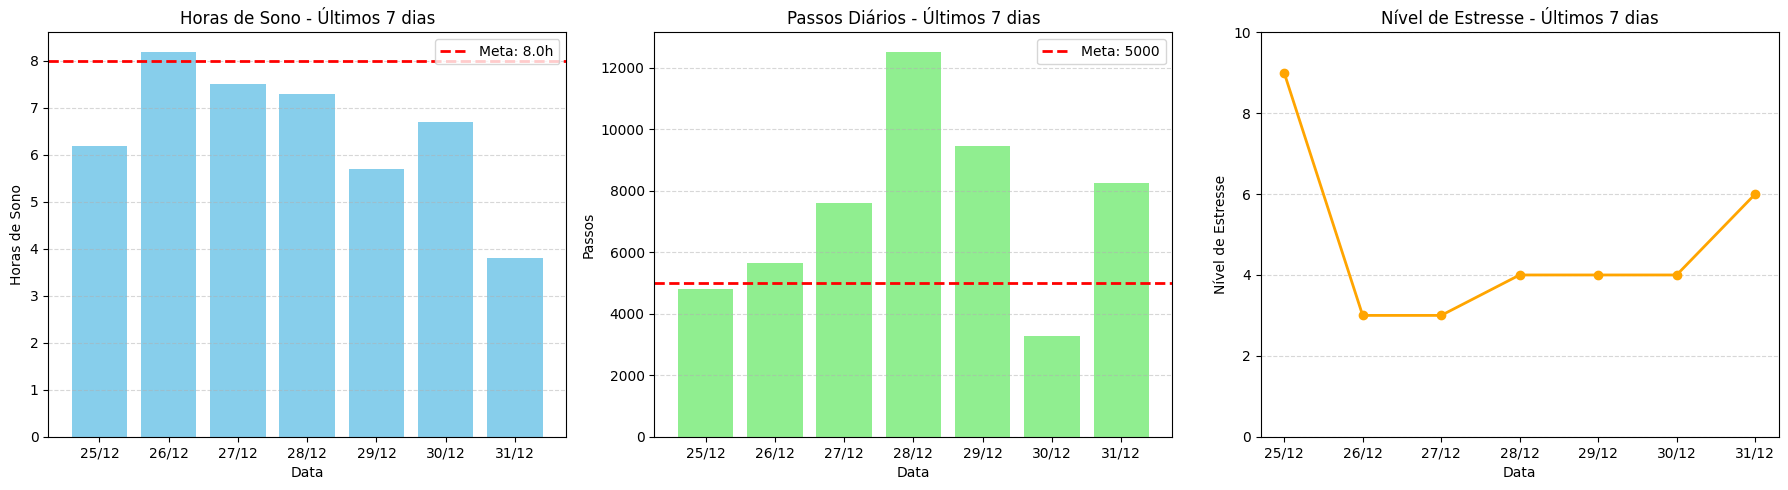

In [ ]:
# Garantindo que os dados estão ordenados por data
last_7days = last_7days.sort_values('date')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Gráfico 1: Horas de Sono por dia, com linha de meta ---
axes[0].bar(last_7days['date'].dt.strftime('%d/%m'), last_7days['sleep_hours'], color='skyblue')
axes[0].axhline(meta_sono, color='red', linestyle='--', linewidth=2, label=f'Meta: {meta_sono:.1f}h')
axes[0].set_title('Horas de Sono - Últimos 7 dias')
axes[0].set_xlabel('Data')
axes[0].set_ylabel('Horas de Sono')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# --- Gráfico 2: Passos Diários, com linha de meta ---
axes[1].bar(last_7days['date'].dt.strftime('%d/%m'), last_7days['daily_steps'], color='lightgreen')
axes[1].axhline(meta_passos, color='red', linestyle='--', linewidth=2, label=f'Meta: {meta_passos:.0f}')
axes[1].set_title('Passos Diários - Últimos 7 dias')
axes[1].set_xlabel('Data')
axes[1].set_ylabel('Passos')
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# --- Gráfico 3: Nível de Estresse ao longo dos dias ---
axes[2].plot(last_7days['date'].dt.strftime('%d/%m'), last_7days['stress_level'],
             marker='o', color='orange', linewidth=2)
axes[2].set_title('Nível de Estresse - Últimos 7 dias')
axes[2].set_xlabel('Data')
axes[2].set_ylabel('Nível de Estresse')
axes[2].set_ylim(0, 10)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('weekly_charts.png', dpi=150)
plt.show()

Top 3 Atividades por Duração Total:
activity_type
Weight Training    199
Dancing            118
Walking             55
Name: activity_duration_min, dtype: int64


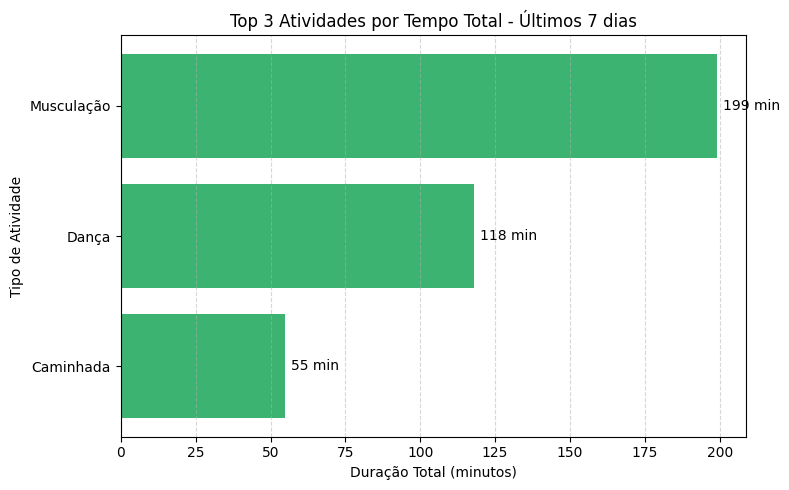


Gráfico salvo como 'emily_top3_exercise.png'


In [ ]:
# 1. Somando a duração total de cada tipo de atividade
duracao_por_atividade = last_7days.groupby('activity_type')['activity_duration_min'].sum()

# 2. Classificando pela duração total e pegando as 3 principais
top3_atividades = duracao_por_atividade.sort_values(ascending=False).head(3)

print("Top 3 Atividades por Duração Total:")
print(top3_atividades)

# 3. Criando o gráfico de barras horizontal (maior no topo)
# Invertendo a ordem para que a maior barra fique no topo do gráfico
top3_ordenado = top3_atividades.sort_values(ascending=True)

nomes_atividades = {
    'Walking': 'Caminhada',
    'HIIT': 'HIIT',
    'Running': 'Corrida',
    'Tennis': 'Tênis',
    'Weight Training': 'Musculação',
    'Dancing': 'Dança',
    'Cycling': 'Ciclismo',
    'Yoga': 'Yoga',
    'Swimming': 'Natação',
    'Basketball': 'Basquete'
}

# Aplicando o mapeamento nos rótulos do top3_ordenado
top3_ordenado.index = top3_ordenado.index.map(nomes_atividades)

plt.figure(figsize=(8, 5))

barras = plt.barh(top3_ordenado.index, top3_ordenado.values, color='mediumseagreen')

plt.title('Top 3 Atividades por Tempo Total - Últimos 7 dias')
plt.xlabel('Duração Total (minutos)')
plt.ylabel('Tipo de Atividade')

# Adicionando rótulos numéricos nas barras
for barra in barras:
    largura = barra.get_width()
    plt.text(largura + (top3_ordenado.max() * 0.01), barra.get_y() + barra.get_height()/2,
              f'{largura:.0f} min', va='center', fontsize=10)

plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()

# 4. Salvando o gráfico
plt.savefig('emily_top3_exercise.png', dpi=150)
plt.show()

print("\nGráfico salvo como 'emily_top3_exercise.png'")

In [ ]:
df['activity_type'].unique()

array(['Walking', 'HIIT', 'Running', 'Tennis', 'Weight Training',
       'Dancing', 'Cycling', 'Yoga', 'Swimming', 'Basketball'],
      dtype=object)